# Contract RAG: Which retrieval method finds the right page?

A retrieval experiment on **10 real commercial contracts** (from the [CUAD dataset](https://www.atticusprojectai.org/cuad), originally filed with the SEC).

The goal of a contract Q&A system is to answer with a citation to the exact **file and page**. If retrieval doesn't bring the right page to the LLM, no model can answer correctly, so this notebook measures retrieval on its own.

**Methods compared**
1. Vector search (`all-MiniLM-L6-v2` embeddings)
2. BM25 keyword search
3. Hybrid: vector + BM25 merged with Reciprocal Rank Fusion (RRF)

**Metric:** Hit@5 = share of questions where the page containing the answer is among the 5 retrieved pages, over a hand-checked set of 33 answerable questions.

Full project (including Claude-generated answers with citations):    **[github.com/oguzhan18m/contract-rag](https://github.com/oguzhan18m/contract-rag)**

## 1. Setup

In [1]:
!pip install -q pymupdf rank_bm25

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 MB 27.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 70.4 MB/s eta 0:00:00


In [2]:
import glob, json, os, re
import numpy as np
import pandas as pd
import pymupdf
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

# Works on Kaggle (files under /kaggle/input) and locally (run from the repo root)
SEARCH_ROOTS = ["/kaggle/input", "."]
pdf_paths = sorted({p for root in SEARCH_ROOTS for p in glob.glob(f"{root}/**/*.pdf", recursive=True)},
                   key=os.path.basename)
questions_path = next(p for root in SEARCH_ROOTS for p in glob.glob(f"{root}/**/questions.jsonl", recursive=True))

print(len(pdf_paths), "PDFs")
print("questions:", questions_path)

10 PDFs
questions: /kaggle/input/datasets/oguzhan18m/cuad-contracts/questions.jsonl


## 2. Ingest: one record per page

Each page is stored with its file name and page number. This metadata is what makes a page-level citation possible later. If it's lost here, it can't be recovered.

In [3]:
def read_pdf(path):
    doc = pymupdf.open(path)
    pages = [{"file": os.path.basename(path), "page": i + 1, "text": page.get_text()}
             for i, page in enumerate(doc)]
    doc.close()
    return pages

pages = [p for path in pdf_paths for p in read_pdf(path)]
pd.DataFrame(pages).groupby("file").size().rename("pages").to_frame()

,pages
file,
01_supply_agape.pdf,13
02_supply_loha.pdf,6
03_supply_reynolds.pdf,16
04_supply_west_pharma.pdf,25
05_service_gpaq.pdf,25
06_service_reynolds.pdf,52
07_manufacturing_inmode.pdf,16
08_manufacturing_upjohn.pdf,82
09_outsourcing_photronics.pdf,11


## 3. Chunking

- Remove the `Source: ...` line that CUAD appends to every page. It repeats on all pages and adds noise.
- Split each page **on its own** into 1,000-character chunks with a 200-character overlap. A chunk never crosses a page boundary, so every citation points to exactly one page.

In [4]:
CHUNK_SIZE, OVERLAP = 1000, 200

def clean_text(text):
    return "\n".join(l for l in text.splitlines() if not l.startswith("Source:")).strip()

def split_text(text, size, overlap):
    chunks, start, step = [], 0, size - overlap
    while start < len(text):
        chunks.append(text[start:start + size])
        if start + size >= len(text):
            break
        start += step
    return chunks

chunks = []
for p in pages:
    for i, t in enumerate(split_text(clean_text(p["text"]), CHUNK_SIZE, OVERLAP)):
        chunks.append({"file": p["file"], "page": p["page"], "chunk_id": f'{p["file"]}-p{p["page"]}-c{i}', "text": t})

lengths = [len(c["text"]) for c in chunks]
print(f"{len(pages)} pages -> {len(chunks)} chunks | avg {np.mean(lengths):.0f} chars, min {min(lengths)}")

317 pages -> 1145 chunks | avg 883 chars, min 48


## 4. Build both indexes

In [5]:
# Vector index: normalized embeddings, so a dot product equals cosine similarity
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
chunk_vecs = model.encode([c["text"] for c in chunks], normalize_embeddings=True,
                          batch_size=64, show_progress_bar=True)

# Keyword index
def tokenize(text):
    return re.findall(r"\w+", text.lower())

bm25 = BM25Okapi([tokenize(c["text"]) for c in chunks])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/18 [00:00<?, ?it/s]

## 5. Retrieval methods

**Reciprocal Rank Fusion (RRF):** each chunk scores `1 / (60 + rank)` in every list it appears in, and the scores are summed. It uses **ranks rather than raw scores**, so the different scales of cosine similarity and BM25 don't matter. A chunk ranked high in both lists wins.

Neighbouring chunks of the same page often both rank high. To give the LLM 5 *different* pages, duplicates are removed.

In [6]:
RRF_K = 60

def vector_search(q, n):
    sims = chunk_vecs @ model.encode(q, normalize_embeddings=True)
    return list(np.argsort(-sims)[:n])

def bm25_search(q, n):
    return list(np.argsort(-bm25.get_scores(tokenize(q)))[:n])

def hybrid_search(q, n):
    scores = {}
    for ranked in (vector_search(q, n), bm25_search(q, n)):
        for rank, idx in enumerate(ranked, start=1):
            scores[idx] = scores.get(idx, 0) + 1 / (RRF_K + rank)
    return sorted(scores, key=scores.get, reverse=True)

def dedupe_pages(indices, k):
    seen, out = set(), []
    for i in indices:
        key = (chunks[i]["file"], chunks[i]["page"])
        if key not in seen:
            seen.add(key)
            out.append(chunks[i])
        if len(out) == k:
            break
    return out

METHODS = {"Vector": vector_search, "BM25": bm25_search, "Hybrid (RRF)": hybrid_search}

def retrieve(q, method, k=5):
    return dedupe_pages(METHODS[method](q, k * 4), k)

## 6. The evaluation set

38 questions written against the contracts. Each answerable question records the file and page that contain the answer, and every expected page was checked to contain the supporting text.

- **33 fact questions** cover term and renewal, governing law, payment, insurance limits, cure periods, warranties, notice periods, and more. Some name the company and some don't. Several ask the same thing about different contracts (e.g. three different cure periods) to test whether the system mixes contracts up.
- **5 trap questions** have no answer in the documents. They test whether the answering model declines instead of guessing, so they are excluded from the retrieval score.

In [7]:
questions = [json.loads(l) for l in open(questions_path)]
facts = [q for q in questions if q["type"] == "fact"]
print(f"{len(facts)} fact questions, {len(questions) - len(facts)} trap questions")
pd.DataFrame(facts)[["id", "question", "file", "page"]].head(8)

33 fact questions, 5 trap questions


,id,question,file,page
0,q01,What is the term of the Agape ATP supply agree...,01_supply_agape.pdf,2
1,q03,How must invoices be paid under the West Pharm...,04_supply_west_pharma.pdf,2
2,q04,Within how many days after signing must the bu...,02_supply_loha.pdf,3
3,q05,When does the term of the Reynolds supply agre...,03_supply_reynolds.pdf,1
4,q06,When does the Constellation services agreement...,05_service_gpaq.pdf,7
5,q07,Which state's law governs the Reynolds service...,06_service_reynolds.pdf,19
6,q08,How is the manufacturing agreement renewed aft...,07_manufacturing_inmode.pdf,1
7,q09,Which state's law governs the Upjohn manufactu...,08_manufacturing_upjohn.pdf,76


## 7. Results

In [8]:
rows = []
for q in facts:
    for method in METHODS:
        got = retrieve(q["question"], method)
        rows.append({"id": q["id"], "method": method,
                     "hit": any(c["file"] == q["file"] and c["page"] == q["page"] for c in got)})
res = pd.DataFrame(rows)

summary = res.groupby("method", sort=False)["hit"].agg(["sum", "count"])
summary["Hit@5"] = (summary["sum"] / summary["count"]).map("{:.0%}".format)
summary.rename(columns={"sum": "hits", "count": "questions"})

,hits,questions,Hit@5
method,,,
Vector,17,33,52%
BM25,22,33,67%
Hybrid (RRF),25,33,76%


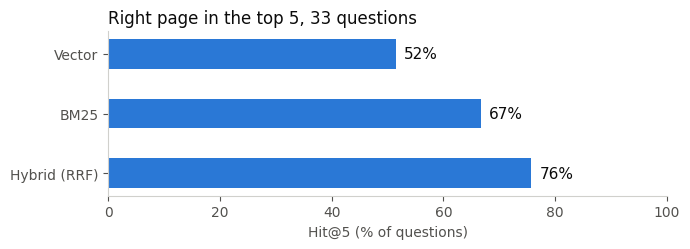

In [9]:
import matplotlib.pyplot as plt

BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"
rates = res.groupby("method", sort=False)["hit"].mean()

fig, ax = plt.subplots(figsize=(7, 2.6))
bars = ax.barh(rates.index[::-1], rates.values[::-1] * 100, color=BLUE, height=0.5)
for bar, v in zip(bars, rates.values[::-1]):
    ax.text(bar.get_width() + 1.5, bar.get_y() + bar.get_height() / 2, f"{v:.0%}",
            va="center", color=INK, fontsize=11)
ax.set_xlim(0, 100)
ax.set_xlabel("Hit@5 (% of questions)", color=MUTED)
ax.set_title(f"Right page in the top 5, {len(facts)} questions", loc="left", color=INK)
ax.tick_params(colors=MUTED)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color("#d0d0cc"); ax.spines["bottom"].set_color("#d0d0cc")
plt.tight_layout(); plt.show()

### Which questions does each method get right?

In [10]:
grid = res.pivot(index="id", columns="method", values="hit")[list(METHODS)]
grid.replace({True: "✅", False: "❌"})

method,Vector,BM25,Hybrid (RRF)
id,,,
q01,❌,✅,✅
q03,❌,❌,❌
q04,✅,✅,✅
q05,❌,❌,✅
q06,❌,✅,✅
q07,❌,❌,❌
q08,✅,✅,✅
q09,❌,❌,❌
q10,❌,✅,✅


In [11]:
missed_by_all = grid.index[~grid.any(axis=1)]
print("Missed by every method:", list(missed_by_all))
pd.DataFrame(facts).set_index("id").loc[missed_by_all, ["question", "file", "page"]]

Missed by every method: ['q03', 'q07', 'q09', 'q15', 'q19', 'q20', 'q23', 'q32']


,question,file,page
id,,,
q03,How must invoices be paid under the West Pharm...,04_supply_west_pharma.pdf,2
q07,Which state's law governs the Reynolds service...,06_service_reynolds.pdf,19
q09,Which state's law governs the Upjohn manufactu...,08_manufacturing_upjohn.pdf,76
q15,What is the term of the West Pharmaceutical su...,04_supply_west_pharma.pdf,4
q19,Which country's law governs the Loha supply ag...,02_supply_loha.pdf,6
q20,Who must insure the goods in the Loha supply a...,02_supply_loha.pdf,3
q23,How are disputes resolved under the ExxonMobil...,04_supply_west_pharma.pdf,11
q32,How long does a party have to cure a material ...,09_outsourcing_photronics.pdf,6


## 8. Findings

**1. Keyword search beats a small embedding model on legal text.** The information that decides an answer sits in exact phrases: *"governed by"*, *"$10,000,000 per occurrence"*, *"thirty (30) days"*. BM25 matches them directly. A small general-purpose embedding model blurs them.

**2. Hybrid is the best trade-off.** RRF finds pages that neither method finds alone, at no extra cost or latency, and it's deterministic.

**3. A negative result: LLM query expansion.** In the full project I also tried rewriting each question into contract wording with Claude before searching. It fixed vocabulary-mismatch cases (asking for the *term* when the contract says *Agreement Period*) but broke a similar number of questions hybrid already answered: 73–76% vs. 76%. On an early 11-question version of the eval set it looked like a clear win. On 33 questions the gain disappeared. It is left out because it adds an LLM call per query and makes results non-deterministic.

**4. What still fails:**

| Failure mode | Example |
|---|---|
| Company name absent from the contract body | The *Loha* contract is written between Chinese trading companies, so "Loha" barely appears in its text |
| Near-duplicate documents | Two Reynolds contracts share a governing law, and the wrong one ranks higher |
| Tables of contents | Upjohn's TOC lists every clause title and outranks the actual clause |
| Clauses inside attachments | ExxonMobil standard terms appended to the West Pharma agreement |

**Next steps:** prepend document and section context to each chunk ("contextual chunk headers"), filter table-of-contents pages, and add a reranker.

**Limitations:** 33 questions is still small, so differences of 1–2 questions are within noise. Results here can differ slightly from the GitHub project, which uses ChromaDB's ONNX build of the same embedding model.